# **ARIMA Modeling - Antarctic Plateau Time Series**

In [1]:
import numpy as np
import pandas as pd

In [2]:
dataset = pd.read_csv('apsrht_datetime.csv', index_col='date_time', parse_dates=True).asfreq('15min')['temp_C']
dataset

date_time
2018-12-19 00:00:00   -20.167
2018-12-19 00:15:00   -20.073
2018-12-19 00:30:00   -19.839
2018-12-19 00:45:00   -19.700
2018-12-19 01:00:00   -19.469
                        ...  
2019-02-02 22:45:00   -34.677
2019-02-02 23:00:00   -34.593
2019-02-02 23:15:00   -34.427
2019-02-02 23:30:00   -34.262
2019-02-02 23:45:00   -34.098
Freq: 15min, Name: temp_C, Length: 4416, dtype: float64

### Preprocessing

In [3]:
### 80/20 split
split_1 = int(len(dataset) * 0.80)
split_2 = int(len(dataset) * 0.90)

train_set = dataset.iloc[:split_1]
validation_set = dataset.iloc[split_1:split_2]
test_set = dataset.iloc[split_2:]

In [4]:
print(f'Training observations:    {len(train_set)}')
print(f'Validation observations:  {len(validation_set)}')
print(f'Testing observations:     {len(test_set)}')

Training observations:    3532
Validation observations:  442
Testing observations:     442


In [5]:
print("Train:")
print(train_set.index.min(), "to", train_set.index.max())

print("\nValidation:")
print(validation_set.index.min(), "to", validation_set.index.max())

print("\nTest:")
print(test_set.index.min(), "to", test_set.index.max())

Train:
2018-12-19 00:00:00 to 2019-01-24 18:45:00

Validation:
2019-01-24 19:00:00 to 2019-01-29 09:15:00

Test:
2019-01-29 09:30:00 to 2019-02-02 23:45:00


### Hyperparameter Tuning

In [6]:
import itertools
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA
import warnings 
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning, ValueWarning

# Suppress specific statsmodels warnings
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", EstimationWarning)
warnings.simplefilter("ignore", ValueWarning)
warnings.filterwarnings("ignore")

In [7]:
def arima_grid_search(train, validation, p_range, d_range, q_range):

    results = []

    for p, d, q in itertools.product(p_range, d_range, q_range):
        try:
            # fit ARIMA model
            model = ARIMA(train, order=(p, d, q)).fit()

            # forecast validation period
            forecast = model.forecast(steps=len(validation))

            # calculate metrics
            rmse = np.sqrt(mean_squared_error(validation, forecast))
            mae = mean_absolute_error(validation, forecast)

            # store results
            results.append({
                'p': p,
                'd': d,
                'q': q,
                'RMSE': rmse,
                'MAE': mae,
                'AIC': model.aic,
                'BIC': model.bic
            })

        except Exception as e:
            print(f'ARIMA({p},{d},{q}) failed: {e}')

    results_df = pd.DataFrame(results)

    if results_df.empty:
        raise ValueError("No ARIMA models fitted successfully.")

    # find parameters with the lowest validation RMSE
    best_row = results_df.loc[results_df['RMSE'].idxmin()]

    return (int(best_row['p']),
            int(best_row['d']),
            int(best_row['q']))



In [8]:
### specifying range of ARIMA parameters; 4*3*4 = 48 total runs
optimized_pdq = arima_grid_search(
    train_set,
    validation_set,
    p_range=range(0, 4),
    d_range=range(0, 3),
    q_range=range(0, 4)
)


In [9]:
optimized_pdq

(0, 1, 3)

---

### Modeling

In [10]:
# initialize history
history = list(train_set)

In [11]:
### training/validation

# walk-forward validation
val_predictions = []
for actual_val in validation_set:
    model = ARIMA(history, order=optimized_pdq)
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    val_predictions.append(yhat)
    
    # Feed the actual validation point back into the history
    history.append(actual_val)

val_rmse = np.sqrt(mean_squared_error(validation_set, val_predictions))
print(f"Validation Set RMSE: {val_rmse:.4f}\n")

Validation Set RMSE: 0.4133



In [12]:
### testing

# test performance on hold-out data
test_predictions = []
for actual_test in test_set:
    model = ARIMA(history, order=optimized_pdq)
    model_fit = model.fit()
    yhat = model_fit.forecast()[0]
    test_predictions.append(yhat)
    
    # Feed the actual test point back into history
    history.append(actual_test)

test_rmse = np.sqrt(mean_squared_error(test_set, test_predictions))
print(f"Final Testing Hold-out RMSE: {test_rmse:.4f}")

Final Testing Hold-out RMSE: 0.3203


In [13]:
### forecasting 

# produce out-of-sample future forecasts
final_model = ARIMA(history, order=optimized_pdq)
final_fit = final_model.fit()
future_forecast = final_fit.forecast(steps=12) # Forecast 12 steps out


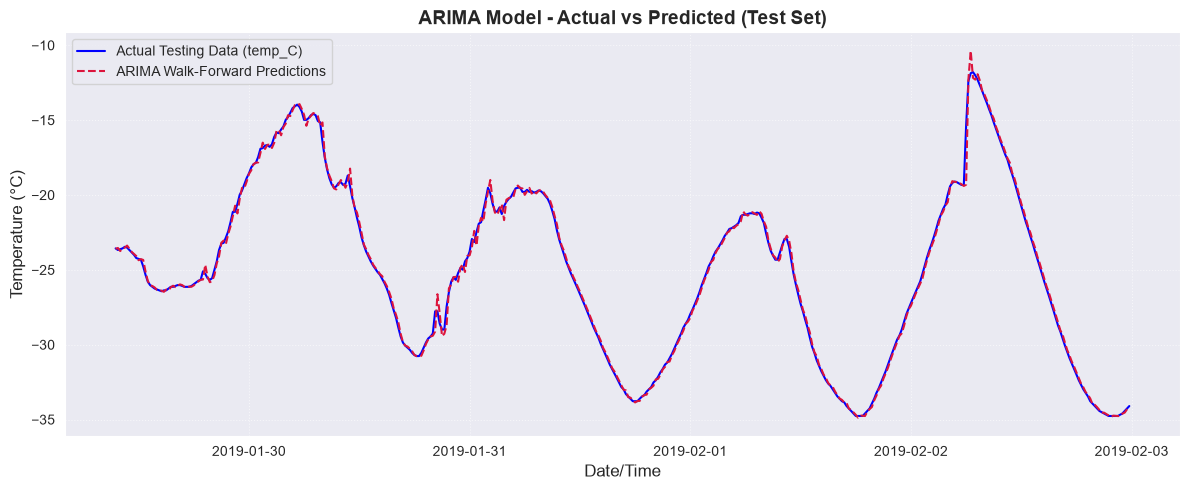

In [21]:
### visualization
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("darkgrid")
plt.figure(figsize=(12, 5))
plt.plot(test_set.index, test_set.values, label="Actual Testing Data (temp_C)", color="blue", linewidth=1.5)
plt.plot(test_set.index, test_predictions, label="ARIMA Walk-Forward Predictions", color="crimson", linestyle="--", linewidth=1.5)
plt.title("ARIMA Model - Actual vs Predicted (Test Set)", fontsize=14, weight="bold")
plt.xlabel("Date/Time", fontsize=12)
plt.ylabel("Temperature (°C)", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()